# Encontro 14. O relatório final: modelo pronto para a sua base (AV3)

**Disciplina:** Métodos e Técnicas de Pesquisa Quantitativa — Administração/UFMA
**Docente:** Prof. Dr. Tadeu Gomes Teixeira

> **O que é este notebook.** É o **molde do relatório final**, já funcionando. Ele traz as
> quatro peças da seção de resultados — Tabela 1, Figura 1, inferência e modelo — sobre uma
> base de exemplo, com a frase de leitura de cada uma escrita ao lado.
>
> **O que você faz hoje**
> 1. **Lê** o relatório de exemplo de cima para baixo: ele mostra o padrão esperado.
> 2. **Troca a base** pela do seu projeto, editando **só os seis valores** da `CONFIG`.
> 3. **Executa tudo** (*Ambiente de execução → Executar tudo*): cada seção se refaz.
> 4. **Escreve** as suas frases de leitura, no lugar indicado, e preenche o registro de IA.

---

## Painel do encontro: a base de exemplo

| Item | Valor |
|---|---|
| **Fonte** | ANP — Série Histórica de Preços de Combustíveis (SHPC), 2025 |
| **Recorte** | Maranhão, gasolina comum, os 12 meses de 2025 |
| **Unidade de observação** | o **posto** (uma linha por posto; o preço é a média dos meses pesquisados) |
| **Observações** | **236 postos** em 11 municípios |
| **Pergunta do exemplo** | O preço da gasolina varia com a **bandeira** do posto ou com a **região**? |

| Coluna | O que quer dizer | Nível |
|---|---|---|
| `preco_gasolina` | preço médio de venda da gasolina comum no ano, em R$ por litro | razão |
| `regiao` | “Ilha de São Luís” (São Luís e São José de Ribamar) ou “Interior” | nominal |
| `bandeira` | “Branca” (sem marca) ou “Com marca” (distribuidora) | nominal |
| `com_marca` | 1 se o posto tem marca, 0 se é bandeira branca | nominal (0/1) |
| `ilha` | 1 se o posto está na Ilha de São Luís, 0 se no interior | nominal (0/1) |
| `vende_etanol` | 1 se a ANP registrou preço de etanol no posto em 2025 | nominal (0/1) |
| `municipio`, `meses_com_preco` | o município e quantos meses o posto foi pesquisado | — |

> **A regra do semestre vale no relatório.** A IA explica, o código calcula e o
> estudante confere e escreve. **Nenhum número entra no relatório sem ter saído de uma
> célula executada.**

## Bloco de configuração: o único lugar que você edita

Os seis valores abaixo definem o relatório inteiro. Para usar a **sua** base, troque-os
e execute tudo de novo. Nada mais muda.

| Valor | No exemplo | Na sua base |
|---|---|---|
| `ARQUIVO` | `"exemplo"` (os postos da ANP) | o nome do seu CSV, depois do upload — ex.: `"minha_base.csv"` |
| `FONTE` | a citação da ANP | a citação da sua fonte, com o ano |
| `RESPOSTA` | `"preco_gasolina"` | a variável **numérica** que a sua pergunta quer descrever e explicar |
| `GRUPO` | `"regiao"` | a variável **categórica** cujos grupos o teste compara |
| `EXPLICATIVAS` | `["com_marca", "ilha"]` | as colunas **numéricas ou 0/1** que entram no modelo |
| `EVENTO` | `"vende_etanol"` | uma coluna **0/1** para a regressão logística, ou `""` para pular a seção |

> **Os nomes precisam ser idênticos aos da base**, com as mesmas letras, sem acento a
> mais nem a menos. O cartão de contexto, logo depois da carga, lista os nomes certos.

In [1]:
# ============================ CONFIG ============================
ARQUIVO      = "exemplo"           # "exemplo" ou o nome do CSV do seu projeto
FONTE        = "ANP, Série Histórica de Preços de Combustíveis (SHPC), 2025"
RESPOSTA     = "preco_gasolina"    # numérica: o que a pergunta quer explicar
GRUPO        = "regiao"            # categórica: os grupos que o teste compara
EXPLICATIVAS = ["com_marca", "ilha"]   # numéricas ou 0/1, para os modelos
EVENTO       = "vende_etanol"      # coluna 0/1 para a logística ("" pula a seção)
# ================================================================

print(f"base: {ARQUIVO} | resposta: {RESPOSTA} | grupo: {GRUPO}")
print(f"explicativas: {EXPLICATIVAS} | evento: {EVENTO or '(sem logística)'}")

base: exemplo | resposta: preco_gasolina | grupo: regiao
explicativas: ['com_marca', 'ilha'] | evento: vende_etanol


## Utilitários da disciplina e do relatório

`conferir` compara um resultado com o valor esperado. As demais funções montam cada
seção do relatório a partir da `CONFIG`. **Não precisa alterar nada nestas duas células.**

> **Como o `conferir` se comporta aqui.** Com a base de exemplo, cada número é conferido
> contra o valor já verificado, e aparece `[ok]`. Com a **sua** base, não há valor
> esperado: aparece `[--]` com o seu número, para você anotar. A conferência que vale
> para qualquer base — **os grupos somam o total** — continua com `[ok]` ou `[X ]`.

In [2]:

# =====================================================================
#  UTILITARIOS DA DISCIPLINA - nao precisa alterar nada daqui para baixo
#  estas duas funcoes sao usadas pelas celulas do encontro. Se voce nao
#  sabe o que elas fazem, tudo bem: nao mexa. Voce so precisa executar.
# =====================================================================

def conferir(descricao, obtido, esperado, tolerancia=0.005, unidade="%"):
    """Confere o resultado calculado contra o valor ja resolvido no slide.

    Chame assim:  conferir("taxa de sobrevivencia do setor X", obtido, 0.412)

    O 'esperado' e o numero que ja estava escrito no slide, resolvido a mao
    pelo professor. Se aparecer [ok], o seu calculo esta certo. Se aparecer
    [X], confira a base, o filtro e a coluna que voce usou.
    """
    try:
        dif = abs(float(obtido) - float(esperado))
    except (TypeError, ValueError):
        print("  [X ] nao deu para comparar: obtido = %r" % (obtido,))
        return
    num = lambda v: ("%.*f%s" % (2, v, unidade)) if unidade else ("%.4f" % v)
    if dif <= tolerancia:
        print("  [ok] %-54s obtido %-9s esperado %s"
              % (descricao[:54], num(float(obtido)), num(float(esperado))))
    else:
        print("  [X ] %-54s obtido %-9s esperado %-9s dif %s"
              % (descricao[:54], num(float(obtido)), num(float(esperado)), num(dif)))


def cartao(df, coluna, nome_base="base"):
    """Imprime o contexto que voce precisa colar no assistente de IA.

    Chame assim:  cartao(dados, "porte")

    Copie a saida inteira e cole no pedido. E isso que impede a IA de
    inventar numero: ela so pode usar o que esta escrito no cartao.
    """
    print("=== CARTAO DE CONTEXTO (copie tudo daqui para o assistente) ===")
    print("base: %s" % nome_base)
    print("linhas x colunas: %d x %d" % df.shape)
    print("colunas e seu significado:")
    for c in df.columns:
        print("   - %s (%s)" % (c, df[c].dtype))
    if coluna in df.columns:
        print("valores unicos de '%s': %s"
              % (coluna, sorted(map(str, df[coluna].dropna().unique()))[:25]))
    print("=== fim do cartao ===")


print("Utilitarios carregados: conferir() e cartao() estao prontas para uso.")


Utilitarios carregados: conferir() e cartao() estao prontas para uso.


In [3]:
# =====================================================================
#  UTILITARIOS DO RELATORIO - nao precisa alterar nada nesta celula
#  sao as funcoes que montam cada secao do relatorio a partir da CONFIG.
#  Se voce nao sabe o que elas fazem, tudo bem: nao mexa. So execute.
# =====================================================================
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

warnings.filterwarnings("ignore")

URL_ANP = ("https://raw.githubusercontent.com/tadeugomes/"
           "metodos-pesquisa-quantitativa/main/dados/anp_precos_revenda_ma_2025.csv")


def _le_csv(caminho):
    """Le um CSV com separador ';' ou ',' detectado sozinho."""
    return pd.read_csv(caminho, sep=None, engine="python", encoding="utf-8-sig")


def _base_exemplo():
    """A base de exemplo: um registro por posto, montado a partir da ANP (SHPC 2025)."""
    try:
        anp = _le_csv(URL_ANP)
    except Exception:
        local = os.path.join("dados", "anp_precos_revenda_ma_2025.csv")
        anp = _le_csv(local if os.path.exists(local) else "anp_precos_revenda_ma_2025.csv")
    anp["cnpj"] = anp["cnpj_da_revenda"].str.strip()
    gas = anp[anp["produto"] == "GASOLINA"]
    postos = (gas.groupby("cnpj")
                 .agg(municipio=("municipio", "first"),
                      bandeira_anp=("bandeira", lambda s: s.mode().iloc[0]),
                      preco_gasolina=("valor_venda", "mean"),
                      meses_com_preco=("mes_arquivo", "nunique"))
                 .reset_index())
    com_etanol = set(anp.loc[anp["produto"] == "ETANOL", "cnpj"])
    postos["vende_etanol"] = postos["cnpj"].isin(com_etanol).astype(int)
    postos["com_marca"] = (postos["bandeira_anp"] != "BRANCA").astype(int)
    postos["bandeira"] = np.where(postos["com_marca"] == 1, "Com marca", "Branca")
    postos["ilha"] = postos["municipio"].isin(["SAO LUIS", "SAO JOSE DE RIBAMAR"]).astype(int)
    postos["regiao"] = np.where(postos["ilha"] == 1, "Ilha de São Luís", "Interior")
    return postos


def carrega(arquivo):
    """'exemplo' devolve a base dos postos; qualquer outro texto e lido como CSV."""
    return _base_exemplo() if arquivo == "exemplo" else _le_csv(arquivo)


def confere(descricao, obtido, esperado_no_exemplo, tolerancia=0.001, unidade=""):
    """No exemplo, confere contra o valor verificado; na base do projeto, so mostra."""
    if ARQUIVO == "exemplo":
        conferir(descricao, obtido, esperado_no_exemplo, tolerancia, unidade)
    elif np.isnan(float(obtido)):
        print("  [--] %-54s não se aplica à sua base" % descricao[:54])
    else:
        print("  [--] %-54s obtido %.4f  (a sua base: anote no relatório)"
              % (descricao[:54], float(obtido)))


def item(objeto, posicao):
    """O valor numa posicao, ou nan quando ele nao existe na sua base."""
    try:
        return float(objeto.iloc[posicao])
    except Exception:
        return float("nan")


def _p(valor):
    return "< 0.001" if valor < 0.001 else "%.4f" % valor


def _linha(nome, s):
    s = s.dropna()
    return {"grupo": nome, "n": len(s), "média": s.mean(), "mediana": s.median(),
            "desvio": s.std(), "CV (%)": s.std() / s.mean() * 100,
            "Q1": s.quantile(0.25), "Q3": s.quantile(0.75)}


def tabela_descritiva(base, resposta, grupo):
    """Tabela 1: a descricao da variavel resposta, no total e em cada grupo."""
    linhas = [_linha("Total", base[resposta])]
    linhas += [_linha(str(g), d[resposta]) for g, d in base.groupby(grupo)]
    return pd.DataFrame(linhas).set_index("grupo").round(3)


def figura(base, resposta, grupo, fonte):
    """Figura 1: a distribuicao da resposta em cada grupo (boxplot)."""
    grupos = [str(g) for g, _ in base.groupby(grupo)]
    dados = [d[resposta].dropna() for _, d in base.groupby(grupo)]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.boxplot(dados, patch_artist=True,
               boxprops=dict(facecolor="#0AB0AB", alpha=0.6),
               medianprops=dict(color="#8D0333", linewidth=2))
    ax.set_xticks(range(1, len(grupos) + 1))
    ax.set_xticklabels(grupos)
    ax.set_xlabel(grupo)
    ax.set_ylabel(resposta)
    ax.set_title("Figura 1. %s por %s" % (resposta, grupo))
    fig.text(0.01, 0.01, "Fonte: " + fonte, fontsize=8)
    plt.tight_layout()
    plt.show()


def inferencia(base, resposta, grupo):
    """Intervalo de 95% de cada grupo e os dois testes que o fluxograma oferece."""
    blocos = [(str(g), d[resposta].dropna()) for g, d in base.groupby(grupo)]
    linhas = []
    for g, s in blocos:
        ep = s.std() / np.sqrt(len(s))
        t = stats.t.ppf(0.975, len(s) - 1)
        linhas.append({"grupo": g, "n": len(s), "média": s.mean(), "erro_padrão": ep,
                       "IC95_inf": s.mean() - t * ep, "IC95_sup": s.mean() + t * ep})
    ics = pd.DataFrame(linhas).set_index("grupo").round(4)
    amostras = [s for _, s in blocos]
    if len(amostras) == 2:
        a = stats.ttest_ind(amostras[0], amostras[1], equal_var=False)
        b = stats.mannwhitneyu(amostras[0], amostras[1], alternative="two-sided")
        nomes = ["t de Welch (compara médias)", "Mann-Whitney (compara postos)"]
    else:
        a = stats.f_oneway(*amostras)
        b = stats.kruskal(*amostras)
        nomes = ["ANOVA (compara médias)", "Kruskal-Wallis (compara postos)"]
    p = [a.pvalue, b.pvalue]
    testes = pd.DataFrame({
        "teste": nomes,
        "estatística": [round(a.statistic, 4), round(b.statistic, 4)],
        "valor_p": [_p(v) for v in p],
        "decisão a 5%": ["rejeita H0" if v < 0.05 else "não rejeita H0" for v in p],
    }).set_index("teste")
    return ics, testes, p


def _cinco_colunas(ajuste, explicativas, efeito):
    return pd.DataFrame({
        "variável": ["intercepto"] + list(explicativas),
        "estimativa": ajuste.params.values.round(4),
        "erro_padrão": ajuste.bse.values.round(4),
        "valor_p": [_p(v) for v in ajuste.pvalues.values],
        "efeito": efeito,
    }).set_index("variável")


def modelo_linear(base, resposta, explicativas):
    """Regressao linear, lida em cinco colunas. Nada de summary() do pacote."""
    d = base[[resposta] + list(explicativas)].dropna()
    ajuste = sm.OLS(d[resposta], sm.add_constant(d[list(explicativas)])).fit()
    efeito = ["valor previsto com tudo em zero"] + [
        "%+.4f na resposta por unidade" % b for b in ajuste.params.values[1:]]
    return _cinco_colunas(ajuste, explicativas, efeito), ajuste


def modelo_logistico(base, evento, explicativas):
    """Regressao logistica em cinco colunas e a probabilidade prevista em cenarios."""
    if not evento:
        print("EVENTO vazio na CONFIG: a seção da regressão logística foi pulada.")
        return (pd.DataFrame(), pd.Series(dtype=float),
                pd.DataFrame(columns=["probabilidade prevista (%)"]))
    d = base[[evento] + list(explicativas)].dropna()
    ajuste = sm.Logit(d[evento], sm.add_constant(d[list(explicativas)])).fit(disp=0)
    razoes = np.exp(ajuste.params.values)
    efeito = ["chance de partida %.4f" % razoes[0]] + [
        "chance x %.4f por unidade" % r for r in razoes[1:]]
    valores = [[0, 1] if set(d[x].unique()) <= {0, 1}
               else [d[x].quantile(0.25), d[x].quantile(0.75)] for x in explicativas]
    grade = pd.MultiIndex.from_product(valores, names=list(explicativas)).to_frame(index=False)
    grade["probabilidade prevista (%)"] = (
        ajuste.predict(sm.add_constant(grade, has_constant="add")) * 100).round(2)
    razoes = pd.Series(razoes, index=["intercepto"] + list(explicativas))
    return _cinco_colunas(ajuste, explicativas, efeito), razoes, grade


print("Utilitarios do relatorio carregados: carrega, confere, tabela_descritiva,")
print("figura, inferencia, modelo_linear, modelo_logistico e item estao prontas.")

Utilitarios do relatorio carregados: carrega, confere, tabela_descritiva,
figura, inferencia, modelo_linear, modelo_logistico e item estao prontas.


## Seção 0. A base

**Glossário do dia**

| Termo | Em uma linha |
|---|---|
| **Tabela 1** | a descrição da variável principal, no total e por grupo: sempre a primeira peça dos resultados |
| **Figura 1** | o gráfico que mostra a **forma** da distribuição em cada grupo, com título, eixos e fonte |
| **Inferência** | o que a amostra autoriza dizer sobre a população: intervalo de confiança e teste |
| **Tabela de cinco colunas** | variável, estimativa, erro padrão, valor-p e efeito: a leitura de um modelo |
| **Razão de chances** | quantas vezes a chance do evento se multiplica quando a explicativa sobe uma unidade |
| **Probabilidade prevista** | a probabilidade do evento num cenário concreto, que é a leitura que o gestor entende |
| **Reprodutível** | outra pessoa executa o notebook do início ao fim e obtém os mesmos números |
| **Frase de leitura** | quanto, em quem, com que incerteza e o que o resultado **não** autoriza |

Execute a carga. Se a internet falhar, use a célula de contingência logo abaixo.

In [4]:
# A carga da base definida na CONFIG.
base = carrega(ARQUIVO)
print(f"base carregada: {base.shape[0]} linhas x {base.shape[1]} colunas")
print(f"colunas: {list(base.columns)}")
print()
confere("observações na base", len(base), 236, tolerancia=0, unidade=" obs")

base carregada: 236 linhas x 10 colunas
colunas: ['cnpj', 'municipio', 'bandeira_anp', 'preco_gasolina', 'meses_com_preco', 'vende_etanol', 'com_marca', 'bandeira', 'ilha', 'regiao']

  [ok] observações na base                                    obtido 236.00 obs esperado 236.00 obs


In [ ]:
# CONTINGÊNCIA — só se a célula de carga falhar por falta de internet (exemplo)
# ou se o seu CSV ainda não estiver no Colab. Execute, escolha o arquivo e, depois,
# execute a célula de carga de novo. Nada mais muda.
from google.colab import files
files.upload()

In [5]:
# O cartão de contexto: os nomes exatos das colunas, para a CONFIG e para a IA.
cartao(base, GRUPO, FONTE)

=== CARTAO DE CONTEXTO (copie tudo daqui para o assistente) ===
base: ANP, Série Histórica de Preços de Combustíveis (SHPC), 2025
linhas x colunas: 236 x 10
colunas e seu significado:
   - cnpj (object)
   - municipio (object)
   - bandeira_anp (object)
   - preco_gasolina (float64)
   - meses_com_preco (int64)
   - vende_etanol (int64)
   - com_marca (int64)
   - bandeira (object)
   - ilha (int64)
   - regiao (object)
valores unicos de 'regiao': ['Ilha de São Luís', 'Interior']
=== fim do cartao ===


> **Dica de estudo**: Troque a base **antes** de escrever qualquer frase: rode a carga com o seu CSV, confira os nomes no cartão e só então edite RESPOSTA, GRUPO, EXPLICATIVAS e EVENTO. Um nome de coluna errado é a causa de quase todo erro desta aula.

---
# O relatório

## 1. Introdução *(no seu relatório: troque pelo seu texto)*

**Problema.** O preço da gasolina pesa no custo de frotas, entregas e deslocamentos, e o
gestor de compras precisa saber onde e de quem comprar. No Maranhão, os postos se dividem
entre os de **bandeira branca** e os **com marca** de distribuidora, e entre a **Ilha de
São Luís** e o **interior**.

**Pergunta de pesquisa.** Em 2025, o preço da gasolina comum nos postos do Maranhão
varia mais com a **bandeira** do posto ou com a **região** onde ele está?

**Objetivo.** Descrever o preço médio anual por posto, comparar as regiões e estimar o
efeito da bandeira mantida a região.

**Hipóteses.** H1: o preço difere entre a Ilha e o interior. H2: mantida a região, os
postos com marca cobram mais que os de bandeira branca.

## 2. Método *(no seu relatório: troque pelo seu texto)*

| Item | No exemplo |
|---|---|
| **Delineamento** | descritivo e correlacional, com dados secundários (observacional: não há sorteio de tratamento) |
| **Fonte** | ANP, Série Histórica de Preços de Combustíveis (SHPC), 2025 |
| **População e amostra** | os postos que a ANP pesquisa no Maranhão: **236 postos** em 11 municípios. A SHPC é um levantamento da ANP, e não um sorteio feito para esta pesquisa: a inferência vale para os postos pesquisados |
| **Unidade de observação** | o posto; o preço é a média dos meses em que o posto foi pesquisado |
| **Variáveis** | `preco_gasolina` (razão, R$/litro); `regiao` e `bandeira` (nominais); `vende_etanol` (0/1) |
| **Técnicas** | Tabela 1 e Figura 1; intervalo de 95% e teste t de Welch, com o Mann-Whitney como confirmação; regressão linear múltipla; regressão logística |
| **Tratamento** | a bandeira de cada posto é a mais frequente no ano (9 postos trocaram de bandeira); nenhum posto foi excluído |
| **Reprodutibilidade** | este notebook, executado do início ao fim, refaz todos os números |

## 3. Resultados

A seção de resultados tem **quatro peças, sempre nesta ordem**: a Tabela 1 (quem são os
casos), a Figura 1 (a forma), a inferência (o que a amostra autoriza) e o modelo (o
efeito de cada variável, mantidas as outras). Cada peça vem com a sua frase de leitura.

### 3.1 Tabela 1: a descrição

A primeira tabela de qualquer relatório quantitativo descreve a variável principal, no
total e em cada grupo. O leitor precisa saber **quantos casos**, **qual o valor típico**
e **quanto os casos variam** antes de qualquer teste.

In [6]:
# Tabela 1: a variável resposta, no total e por grupo.
tabela1 = tabela_descritiva(base, RESPOSTA, GRUPO)
display(tabela1)

conferir("os grupos somam o total", tabela1["n"].iloc[1:].sum(), tabela1["n"].iloc[0],
         tolerancia=0, unidade=" obs")
confere("média do total", base[RESPOSTA].mean(), 5.9744)
confere("média do primeiro grupo", item(tabela1["média"], 1), 5.703)
confere("média do segundo grupo", item(tabela1["média"], 2), 6.313)

,n,média,mediana,desvio,CV (%),Q1,Q3
grupo,,,,,,,
Total,236,5.974,5.807,0.375,6.285,5.681,6.235
Ilha de São Luís,131,5.703,5.690,0.118,2.071,5.640,5.766
Interior,105,6.313,6.254,0.304,4.814,6.119,6.535


  [ok] os grupos somam o total                                obtido 236.00 obs esperado 236.00 obs
  [ok] média do total                                         obtido 5.9744    esperado 5.9744
  [ok] média do primeiro grupo                                obtido 5.7030    esperado 5.7030
  [ok] média do segundo grupo                                 obtido 6.3130    esperado 6.3130


**A frase de leitura do exemplo**

> “Em 2025, o preço médio anual da gasolina comum nos **236 postos** pesquisados pela ANP
> no Maranhão foi de **R$ 5,97 por litro** (mediana de R$ 5,81). Na Ilha de São Luís (131
> postos), a média foi de **R$ 5,70**, com desvio padrão de R$ 0,12; no interior (105
> postos), de **R$ 6,31**, com desvio de R$ 0,30. O interior é mais caro e mais desigual
> entre os postos (CV de 4,8% contra 2,1%) (ANP, SHPC, 2025).”

**A sua frase** _(escreva aqui, com o n, a unidade e a fonte)_

---

### 3.2 Figura 1: a forma

Um gráfico por pergunta, e o gráfico que mostra a **distribuição**, não só a média. Toda
figura tem número, título, eixos com unidade e fonte.

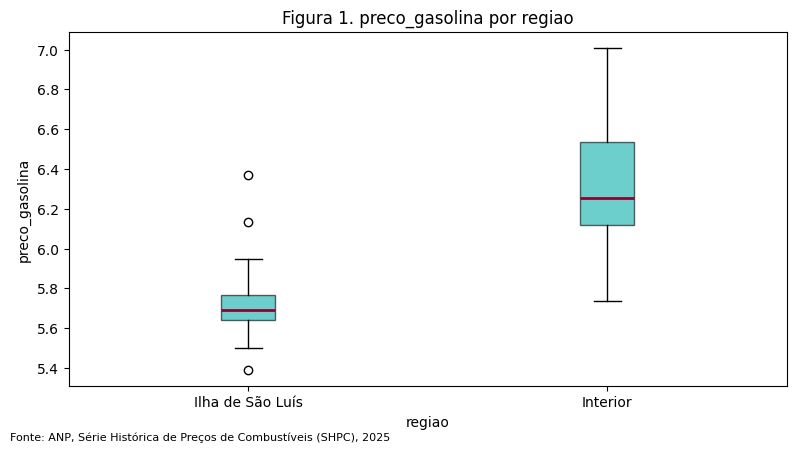

In [7]:
# Figura 1: a distribuição da resposta em cada grupo.
figura(base, RESPOSTA, GRUPO, FONTE)

**A legenda do exemplo**

> *Figura 1. Distribuição do preço médio anual da gasolina comum por posto, segundo a
> região, Maranhão, 2025 (n = 236). Fonte: ANP, SHPC.* As duas caixas não se sobrepõem:
> o posto mais caro da Ilha cobra menos que a maioria dos postos do interior.

**A sua legenda** _(o que a figura mostra, em quem, com que fonte)_

---

### 3.3 Inferência: o que os dados autorizam

O notebook calcula o intervalo de 95% de cada grupo e **os dois testes** que o
fluxograma oferece: o paramétrico (t de Welch, ou ANOVA com três ou mais grupos) e o de
postos (Mann-Whitney, ou Kruskal-Wallis). **Você escolhe qual relatar**, pelo
fluxograma: distribuição aproximadamente simétrica e grupos grandes, o paramétrico;
assimetria forte, grupos pequenos ou variável ordinal, o de postos. Quando os dois
concordam, diga isso: é um argumento a mais.

In [8]:
# Inferência: intervalo de 95% por grupo e os dois testes do fluxograma.
ics, testes, p = inferencia(base, RESPOSTA, GRUPO)
display(ics)
display(testes)
print(f"diferença entre as médias dos dois primeiros grupos: "
      f"{ics['média'].iloc[1] - ics['média'].iloc[0]:+.4f}")

confere("limite inferior do IC do primeiro grupo", item(ics["IC95_inf"], 0), 5.6824,
        tolerancia=0.0001)
confere("limite superior do IC do primeiro grupo", item(ics["IC95_sup"], 0), 5.7233,
        tolerancia=0.0001)
confere("estatística do teste paramétrico", item(testes["estatística"], 0), -19.4379,
        tolerancia=0.0001)

,n,média,erro_padrão,IC95_inf,IC95_sup
grupo,,,,,
Ilha de São Luís,131,5.7029,0.0103,5.6824,5.7233
Interior,105,6.3132,0.0297,6.2544,6.3720


,estatística,valor_p,decisão a 5%
teste,,,
t de Welch (compara médias),-19.4379,< 0.001,rejeita H0
Mann-Whitney (compara postos),270.5000,< 0.001,rejeita H0


diferença entre as médias dos dois primeiros grupos: +0.6103
  [ok] limite inferior do IC do primeiro grupo                obtido 5.6824    esperado 5.6824
  [ok] limite superior do IC do primeiro grupo                obtido 5.7233    esperado 5.7233
  [ok] estatística do teste paramétrico                       obtido -19.4379  esperado -19.4379


**A frase de leitura do exemplo**

> “O preço médio da gasolina é **R$ 0,61 por litro maior** no interior que na Ilha de
> São Luís. Os intervalos de 95% não se sobrepõem (Ilha: R$ 5,68 a R$ 5,72; interior:
> R$ 6,25 a R$ 6,37), e o teste t de Welch rejeita a igualdade das médias (t = −19,44;
> p < 0,001), resultado confirmado pelo Mann-Whitney (p < 0,001).”

**O que essa frase não diz.** Que a região **causa** o preço: o interior tem frete
maior, menos concorrência e outros fornecedores, e o dado não separa essas razões.

**A sua frase** _(o teste que você escolheu e por quê; a diferença na unidade original)_

---

> **Dica de estudo**: O teste se escolhe pelo **fluxograma**, antes de olhar o valor-p. Escolher o teste que deu o p menor é a forma mais comum de fraude involuntária em relatório.

### 3.4 O modelo linear: o efeito de cada variável, mantidas as outras

A regressão responde o que o teste não responde: **quanto** a resposta muda com cada
explicativa, **mantidas as demais**. A leitura é sempre a da tabela de cinco colunas.

| Coluna | Como se lê |
|---|---|
| `estimativa` | quanto a resposta muda quando a variável sobe uma unidade (de 0 para 1, se for 0/1) |
| `erro_padrão` | a incerteza da estimativa: de amostra para amostra, ela varia cerca disso |
| `valor_p` | a chance de uma estimativa tão longe de zero se o efeito verdadeiro fosse zero |
| `efeito` | a estimativa traduzida em frase curta, na unidade da resposta |

In [9]:
# O modelo linear: a resposta explicada pelas EXPLICATIVAS, em cinco colunas.
tabela_lin, ajuste_lin = modelo_linear(base, RESPOSTA, EXPLICATIVAS)
display(tabela_lin)
print(f"n = {int(ajuste_lin.nobs)} | R² = {ajuste_lin.rsquared:.4f}")

confere("coeficiente da primeira explicativa", item(ajuste_lin.params, 1), 0.0507,
        tolerancia=0.0001)
confere("valor-p da primeira explicativa", item(ajuste_lin.pvalues, 1), 0.0788,
        tolerancia=0.0001)
confere("coeficiente da segunda explicativa", item(ajuste_lin.params, 2), -0.6139,
        tolerancia=0.0001)
confere("R² do modelo", ajuste_lin.rsquared, 0.6599, tolerancia=0.0001)

,estimativa,erro_padrão,valor_p,efeito
variável,,,,
intercepto,6.2901,0.0252,< 0.001,valor previsto com tudo em zero
com_marca,0.0507,0.0287,0.0788,+0.0507 na resposta por unidade
ilha,-0.6139,0.0289,< 0.001,-0.6139 na resposta por unidade


n = 236 | R² = 0.6599
  [ok] coeficiente da primeira explicativa                    obtido 0.0507    esperado 0.0507
  [ok] valor-p da primeira explicativa                        obtido 0.0788    esperado 0.0788
  [ok] coeficiente da segunda explicativa                     obtido -0.6139   esperado -0.6139
  [ok] R² do modelo                                           obtido 0.6599    esperado 0.6599


**A frase de leitura do exemplo**

> “Mantida a região, os postos com marca cobram em média **R$ 0,05 a mais por litro** que
> os de bandeira branca, diferença que não é estatisticamente significativa a 5%
> (p = 0,079). Mantida a bandeira, estar na Ilha de São Luís está associado a um preço
> **R$ 0,61 menor** (p < 0,001). As duas variáveis acompanham **66%** da variação do
> preço entre os postos (R² = 0,66; n = 236).”

**A sua frase** _(a estimativa na unidade da resposta, o “mantidas as demais”, o p e o R²)_

---

### A leitura crítica: o mesmo coeficiente, sem controlar a região

O que o número diz depende do que está no modelo. A célula abaixo ajusta o modelo
**só com a primeira explicativa** — a comparação crua, sem controle.

In [10]:
# A comparação crua: o modelo só com a primeira explicativa.
tabela_crua, ajuste_cru = modelo_linear(base, RESPOSTA, EXPLICATIVAS[:1])
display(tabela_crua)
print(f"n = {int(ajuste_cru.nobs)} | R² = {ajuste_cru.rsquared:.4f}")

confere("coeficiente sem controle", item(ajuste_cru.params, 1), 0.0085, tolerancia=0.0001)
confere("valor-p sem controle", item(ajuste_cru.pvalues, 1), 0.8630, tolerancia=0.0001)

,estimativa,erro_padrão,valor_p,efeito
variável,,,,
intercepto,5.9702,0.0345,< 0.001,valor previsto com tudo em zero
com_marca,0.0085,0.0490,0.8630,+0.0085 na resposta por unidade


n = 236 | R² = 0.0001
  [ok] coeficiente sem controle                               obtido 0.0085    esperado 0.0085
  [ok] valor-p sem controle                                   obtido 0.8630    esperado 0.8630


**O que muda e por quê.** Sem controlar a região, a diferença por bandeira é de
**R$ 0,01** (p = 0,863): parece não haver diferença nenhuma. Com a região no modelo, ela
sobe para **R$ 0,05** (p = 0,079). A razão é que os postos com marca estão mais na Ilha,
onde a gasolina é mais barata (70 de 117 postos com marca, contra 61 de 119 de bandeira
branca): a região **esconde** parte do efeito da bandeira. É a variável de confusão do
encontro 6, agora dentro de um modelo.

**Duas lições para o relatório:** (1) “não significativo” não quer dizer “igual” — o
teste cru dizia p = 0,863 e o efeito não era zero; (2) diga sempre **o que foi
controlado** — o coeficiente muda com o que está ao lado dele.

---

### 3.5 O modelo logístico: quando a resposta é sim ou não

Quando a pergunta é sobre um **evento** (sobreviveu, ficou inadimplente, vende etanol), a
resposta é 0/1 e o modelo é a regressão logística. A coluna `efeito` traz a **razão de
chances**: acima de 1, a chance aumenta; abaixo de 1, diminui. Para o gestor, a leitura
mais clara é a **probabilidade prevista** em cenários concretos, que a célula também
calcula.

> **Um cuidado de medida no exemplo.** `vende_etanol` vale 1 quando a ANP **registrou**
> preço de etanol no posto. A ANP pesquisa uma amostra de postos e produtos: um posto pode
> vender etanol sem ter sido pesquisado nesse produto. A frase precisa dizer isso.

In [11]:
# O modelo logístico: o EVENTO explicado pelas EXPLICATIVAS, em cinco colunas.
tabela_log, razoes, cenarios = modelo_logistico(base, EVENTO, EXPLICATIVAS)
display(tabela_log)
display(cenarios)

prob = cenarios["probabilidade prevista (%)"]
confere("razão de chances da primeira explicativa", item(razoes, 1), 1.3450,
        tolerancia=0.0001)
confere("razão de chances da segunda explicativa", item(razoes, 2), 2.0294,
        tolerancia=0.0001)
confere("probabilidade no primeiro cenário (%)", item(prob, 0), 49.97, tolerancia=0.01)
confere("probabilidade no último cenário (%)", item(prob, -1), 73.16, tolerancia=0.01)

,estimativa,erro_padrão,valor_p,efeito
variável,,,,
intercepto,-0.0012,0.2321,0.9959,chance de partida 0.9988
com_marca,0.2964,0.2747,0.2805,chance x 1.3450 por unidade
ilha,0.7077,0.2744,0.0099,chance x 2.0294 por unidade


,com_marca,ilha,probabilidade prevista (%)
0,0,0,49.97
1,0,1,66.96
2,1,0,57.33
3,1,1,73.16


  [ok] razão de chances da primeira explicativa               obtido 1.3450    esperado 1.3450
  [ok] razão de chances da segunda explicativa                obtido 2.0294    esperado 2.0294
  [ok] probabilidade no primeiro cenário (%)                  obtido 49.9700   esperado 49.9700
  [ok] probabilidade no último cenário (%)                    obtido 73.1600   esperado 73.1600


**A frase de leitura do exemplo**

> “Mantida a bandeira, a chance de a ANP registrar preço de etanol é **2,03 vezes maior**
> nos postos da Ilha de São Luís que nos do interior (p = 0,010); a bandeira não mostra
> associação significativa (razão de chances de 1,35; p = 0,281). Em probabilidade, um
> posto de bandeira branca no interior tem **50,0%** de chance prevista de ter o etanol
> pesquisado, e um posto com marca na Ilha, **73,2%**.”

**O que essa frase não diz.** Que a Ilha “faz” o posto vender etanol, nem que a
probabilidade dobra: **razão de chances não é razão de probabilidades** (50,0% → 66,96%
na Ilha, mantida a bandeira branca, não 100%).

**A sua frase** _(a razão de chances com o “mantidas as demais” e uma probabilidade prevista)_

---

> **Dica de estudo**: Se a sua pergunta não tem resposta sim/não, escreva `EVENTO = ""` na CONFIG: a seção é pulada e o relatório fica com o modelo linear. Não invente um evento para usar a logística.

## 4. Discussão e limitações *(no seu relatório: troque pelo seu texto)*

**O que o exemplo responde.** O preço da gasolina no Maranhão, em 2025, varia muito mais
com a **região** que com a **bandeira**: a diferença entre o interior e a Ilha é de
R$ 0,61 por litro, e a bandeira, mantida a região, acrescenta R$ 0,05, sem significância
a 5%. Para o gestor de compras de uma frota, onde abastecer pesa mais que em quem.

**O que o exemplo não autoriza.**
1. **Causa.** O dado é observacional: frete, concorrência e escala não estão no modelo.
2. **Generalizar para todos os postos do estado.** A SHPC é um levantamento da ANP em
   11 municípios, e não um sorteio do cadastro de postos.
3. **Ler o preço médio do ano como o preço de hoje.** É a média dos meses pesquisados.
4. **Ler `vende_etanol` como mix de produtos.** É o registro da pesquisa, não do posto.

**Agenda.** Acrescentar o frete (distância até a base de distribuição) e a concorrência
(postos por município) ao modelo.

---
# Guia de redação: da pergunta à frase

Encontre a linha da sua pergunta, use a estatística da terceira coluna e escreva a frase
no formato da quarta. **Se a sua pergunta não está na tabela, o problema é de
delineamento, e não de redação** — fale com o professor antes de escrever.

| Módulo | A pergunta | A estatística | O formato da frase |
|---|---|---|---|
| I | Quantos são de cada tipo? | frequência e porcentagem, com o denominador declarado | “Entre os n casos, x% (k) são do tipo A” |
| I | Qual a taxa dentro de cada grupo? | proporção por linha; diferença em pontos percentuais | “x% no grupo A contra y% no B: d pontos percentuais a mais” |
| I | Qual o valor típico? | média (simétrica) ou mediana (assimétrica ou ordinal) | “A mediana foi de m; metade dos casos entre Q1 e Q3” |
| I | Quanto os casos variam? | desvio padrão, CV, intervalo interquartílico | “Média de x, desvio de s (CV de c%), em n casos” |
| I | Este caso é atípico? | escore z | “O caso c está z desvios padrão acima da média” |
| II | Quanto vale para a população? | erro padrão e margem de erro | “Estimativa de x, margem de m a 95% (amostra aleatória de n)” |
| II | Quantos casos são precisos? | tamanho da amostra | “Para margem de m a 95%, são necessários n casos” |
| II | Os itens medem a mesma coisa? | alfa de Cronbach | “Escala de k itens, alfa de a” |
| III | Entre que valores está o parâmetro? | intervalo de confiança | “Entre a e b, com 95% de confiança no método” |
| III | Dois grupos diferem? | t de Welch ou Mann-Whitney | “Diferença de d (unidade); t = _, p = _” |
| III | Três ou mais grupos diferem? | ANOVA ou Kruskal-Wallis | “As médias diferem entre os k grupos (F = _, p = _)” |
| III | Duas categóricas se associam? | qui-quadrado | “x% contra y%; χ² = _, gl = _, p = _” |
| IV | As duas variáveis andam juntas? | correlação r | “r = _: associação positiva e forte, que não é causa” |
| IV | Quanto Y muda com X, mantido Z? | regressão linear, em cinco colunas | “A cada unidade de X, Y muda b, mantido Z (p = _); R² = _” |
| IV | Qual a chance de um evento? | regressão logística: razão de chances e probabilidade prevista | “A chance é OR vezes maior com X; probabilidade prevista de p% no cenário C” |

## O teste das quatro perguntas

Antes de dar uma frase por pronta, verifique se ela diz:

1. **Quanto** — o número, com a unidade;
2. **Em quem** — o n, o recorte e o período;
3. **Com que incerteza** — o intervalo, o erro padrão ou o valor-p;
4. **O que não autoriza** — causa, generalização, o que ficou de fora.

Se faltar uma das quatro, reescreva.

# A apresentação de 3 a 5 minutos

Um slide — no máximo dois, se o segundo for a Figura 1 — e cinco blocos de cerca de um
minuto cada.

| Bloco | O que dizer | No exemplo |
|---|---|---|
| 1. **A pergunta** | o problema de gestão e a pergunta, em uma frase | “O preço da gasolina varia com a bandeira ou com a região?” |
| 2. **O dado** | fonte, recorte, unidade e n | “ANP, 2025, 236 postos do Maranhão” |
| 3. **O achado** | **um** número, com a frase completa, e a figura | “R$ 0,61 a mais no interior; a bandeira acrescenta R$ 0,05, sem significância” |
| 4. **O limite** | o que o resultado não autoriza | “Não é causa; vale para os postos pesquisados” |
| 5. **A implicação** | o que um gestor faria com isso | “Na compra para a frota, a região pesa mais que a bandeira” |

> **Quem lê o slide não está apresentando.** O slide organiza; a fala comunica. Números
> grandes, uma figura só e nenhuma tabela de cinco colunas projetada inteira.

# Como a AV3 é avaliada

| Peça | Critério | Pontos |
|---|---|---|
| **Relatório** (50) | Pergunta, método e variáveis coerentes, com o nível de cada variável | 10 |
| | Tabela 1 e Figura 1 corretas, com n, unidade e fonte | 10 |
| | Inferência: teste escolhido pelo fluxograma e lido sem erro (IC e valor-p) | 10 |
| | Modelo lido em cinco colunas, efeito na unidade original, sem verbo causal | 10 |
| | Limitações: o que o resultado **não** autoriza | 5 |
| | Frases de leitura completas (o teste das quatro perguntas) | 5 |
| **Notebook** (25) | Executa do início ao fim sem erro (*Reiniciar e executar tudo*) | 10 |
| | `CONFIG` preenchida e a base do projeto carregando (ou a contingência declarada) | 5 |
| | Conferências executadas: os grupos somam o total, e os números do relatório são os do notebook | 5 |
| | Registro de IA preenchido, ou marcado “não usei” | 5 |
| **Apresentação** (25) | Tempo entre 3 e 5 minutos | 5 |
| | Os cinco blocos: pergunta, dado, achado, limite, implicação | 10 |
| | O número principal dito com a frase completa | 5 |
| | Resposta a uma pergunta da turma ou do professor | 5 |
| | **Total** | **100** |

# Registro de uso de IA

**Obrigatório para quem usou o assistente** na AV3. Uma linha por pedido, ou “não usei”.
O registro **não desconta pontos**; a omissão é falta de honestidade acadêmica.

| Modo | O que eu pedi (o prompt, resumido) | Como conferi a resposta | O que eu mudei |
|---|---|---|---|
| | | | |
| | | | |

**Os três modos de uso**, para preencher a primeira coluna:

| Modo | O que você faz | Como se confere |
|---|---|---|
| **Pergunta** | uma pergunta conceitual, com o cartão de contexto colado | a resposta tem de citar um número que está no cartão |
| **Encomenda** | pede, em uma frase, uma mudança de coluna, filtro ou agrupamento e cola o código na célula indicada | o número bate com o esperado; os grupos somam o total; o gráfico é o pedido |
| **Leitura de resultado** | pede ajuda para ler uma saída do notebook | a frase final é sua, e cada número dela está numa saída executada |

# Checklist de entrega da AV3

**O notebook**
- [ ] A `CONFIG` aponta para a **minha** base, e a carga funciona
- [ ] *Ambiente de execução → Reiniciar e executar tudo* roda sem erro
- [ ] A conferência “os grupos somam o total” deu `[ok]`
- [ ] Cada número do relatório está numa saída executada deste notebook

**O relatório**
- [ ] Introdução com a pergunta em forma de pergunta e as hipóteses
- [ ] Método com fonte, recorte, unidade de observação, n e o nível de cada variável
- [ ] Resultados nas quatro peças, nesta ordem: Tabela 1, Figura 1, inferência, modelo
- [ ] Cada resultado com a frase de leitura que passa no teste das quatro perguntas
- [ ] Nenhum verbo causal sobre dado observacional (“aumenta”, “causa”, “provoca”)
- [ ] Discussão com as limitações

**A apresentação**
- [ ] Um slide (no máximo dois), cinco blocos, ensaiada em menos de 5 minutos

**A transparência**
- [ ] O registro de IA está preenchido, ou marcado “não usei”
- [ ] O link do notebook foi **compartilhado** com o professor

> Guarde este notebook. **Ele é o seu relatório reprodutível**: quem o executar refaz
> cada número que você escreveu.